# Steam Analyzer

This project aims to analyze trends in Steams discount strategy and predict price on games in the future based on it.

[Dataset](https://www.kaggle.com/datasets/benjaminlundkvist/steam-sales-historical-dataset)


# Imports

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

# Data preparation

In [103]:
df = pd.read_csv("data/steam_prices_reviews.csv", parse_dates=["month", "release_date"])

df = df[df["base_price"] > 0]  # remove division by zero
df = df[df["lowest_price"] > 0]  # remove zero or negative prices
df = df[df["lowest_price"] <= df["base_price"]]  # remove negative discounts

# Discount percentage
df["discount_percent"] = (1 - df["lowest_price"] / df["base_price"]) * 100

# Days since release
df["days_since_release"] = (df["month"] - df["release_date"]).dt.days

# Review ratios
df["positive_ratio"] = df["positive"] / df["total_reviews"]
df["negative_ratio"] = df["negative"] / df["total_reviews"]

# Convert review_change_percent from string to numeric
df["review_change_percent"] = (
    df["review_change_percent"]
    .str.replace("-", "0")
    .str.replace("%", "", regex=False)
    .astype(float)
)

# Monthly averages
monthly = df.groupby("month").agg(
    avg_discount=("discount_percent", "mean"),
    avg_days_on_sale=("days_on_sale", "mean"),
    avg_review_change=("review_change_percent", "mean"),
    avg_positive_ratio=("positive_ratio", "mean"),
).reset_index()

monthly.head()

,month,avg_discount,avg_days_on_sale,avg_review_change,avg_positive_ratio
0,2023-11-01,54.120446,9.709091,0.306591,0.865255
1,2023-12-01,55.724852,11.188341,0.170493,0.864467
2,2024-01-01,54.823126,5.070485,0.239824,0.863837
3,2024-02-01,35.528540,3.097778,0.323511,0.865745
4,2024-03-01,53.252675,7.811159,0.560343,0.860828


# Data Visualisation

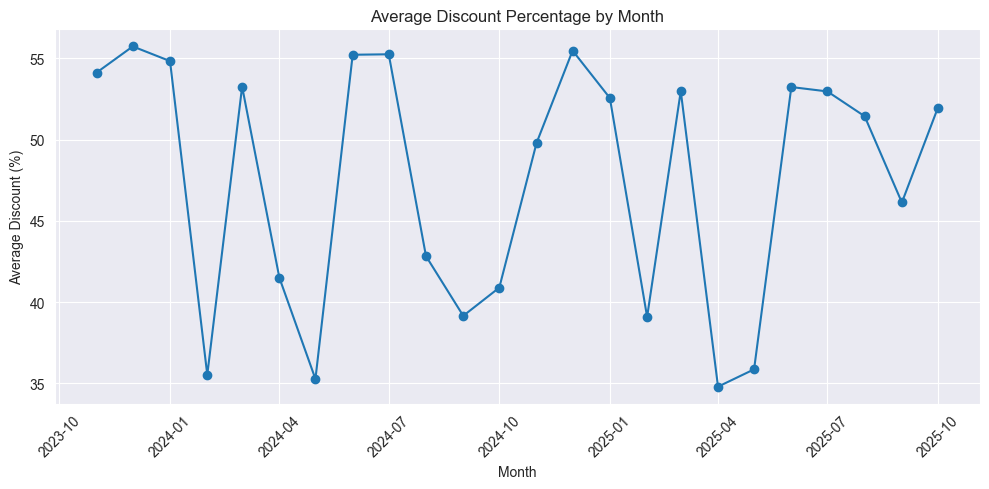

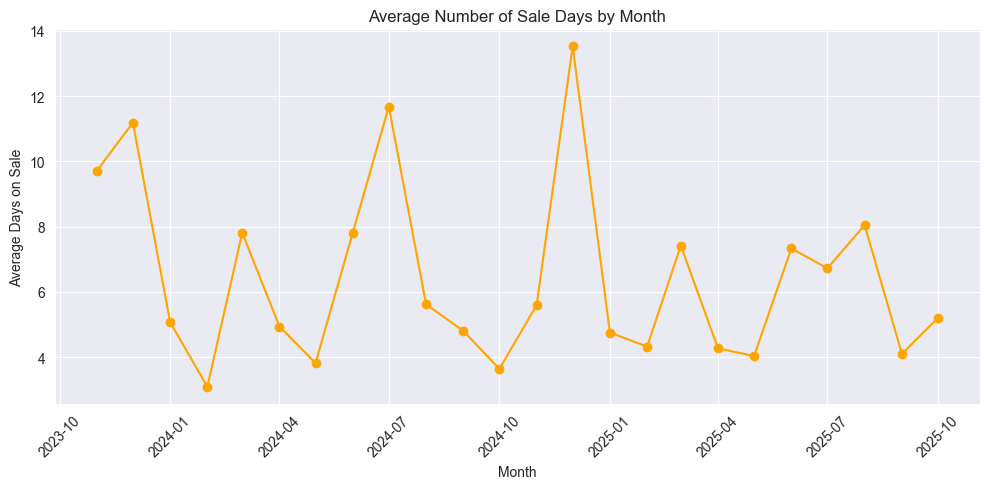

In [104]:
# --- Plot 1: Average discount percentage per month ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_discount"], marker="o")
plt.title("Average Discount Percentage by Month")
plt.xlabel("Month")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 2: Average number of sale days per month ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_days_on_sale"], marker="o", color="orange")
plt.title("Average Number of Sale Days by Month")
plt.xlabel("Month")
plt.ylabel("Average Days on Sale")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The two graphs show a clear positive correlation — months with higher average discounts also tend to have more sale days.
This suggests that major seasonal sales drive both deeper and longer discounts across the platform.

According to these graphs, highest discounts are mostly common in times of major sales,
For example winter 2023-2024 and early autumn 2024 have discounts up to 55%. Its the same for summer 2024 and winter 2024-2025.


The graph also shows, that summer sale 2025 was somewhat short, compared to other years. That suggests, that future user recommendations better include timeperiod instead of just season

Also, October 2025 seems to have low amount of days per sale, however discount reaches over 50%, which is strange.

This anomaly in October 2025 is likely explained by short but major promotions — for example, Space Marine 2 (-50%), Darktide (-60%), and Hunt: Showdown (-60%) all had discounts between late September and early October. These brief yet high-impact sales caused a spike in average discount percentage despite the low number of sale days.

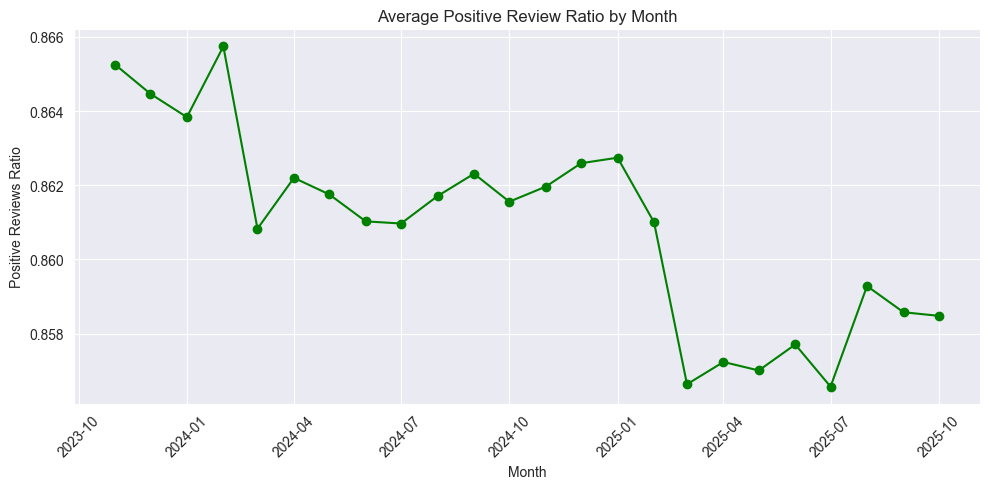

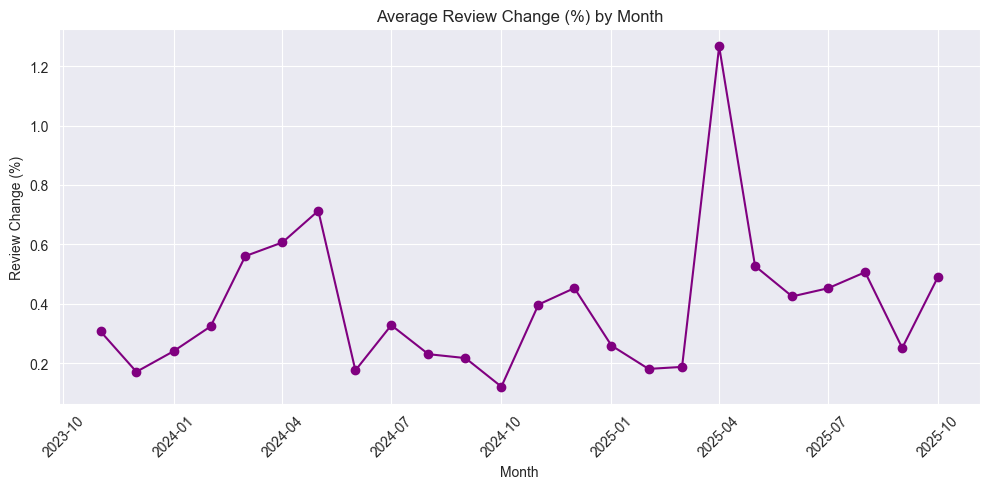

In [105]:
# --- Plot 3: Average positive ratio over time ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_positive_ratio"], marker="o", color="green")
plt.title("Average Positive Review Ratio by Month")
plt.xlabel("Month")
plt.ylabel("Positive Reviews Ratio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 4: Review change percentage ---
plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["avg_review_change"], marker="o", color="purple")
plt.title("Average Review Change (%) by Month")
plt.xlabel("Month")
plt.ylabel("Review Change (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Season sales heatmap

Due to lack of full information regarding 2023 and 2025, comparison of all three of them is not possible, but its possible to compare those years with 2024

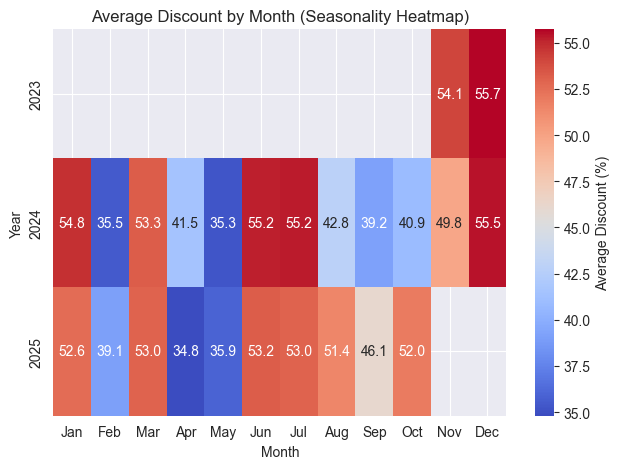

In [106]:
pivot = (
    df.assign(
        year=df['month'].dt.year,
        month_name=df['month'].dt.strftime('%b')
    )
    .groupby(['year', 'month_name'])['discount_percent']
    .mean()
    .unstack()
    .reindex(columns=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
)

sns.heatmap(pivot, cmap="coolwarm", annot=True, fmt=".1f", cbar_kws={'label': 'Average Discount (%)'})
plt.title("Average Discount by Month (Seasonality Heatmap)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


its clearly seen: mostly discounts are the same, with small errors up to 3.5 procents. However, late summer and early autumn sales in 2025 (and 2023 in case of october) are 10% higher compared to 2024

However, april 2024 is 6% higher than april 2025. It may add some noise

# Distribution of discounts

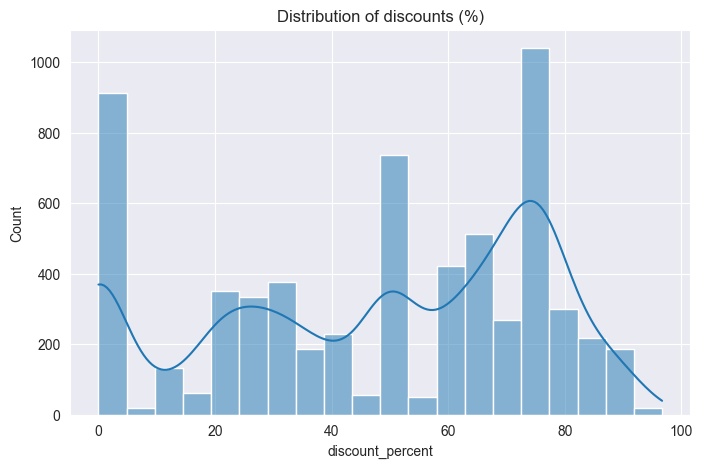

In [107]:
plt.figure(figsize=(8,5))
sns.histplot(df['discount_percent'], bins=20, kde=True)
plt.title("Distribution of discounts (%)")
plt.show()

Most games receive moderate to high discounts, especially around 50–80%. The data confirms that heavy discounts are quite common, possibly due to regular store-wide sales or frequent price adjustments.

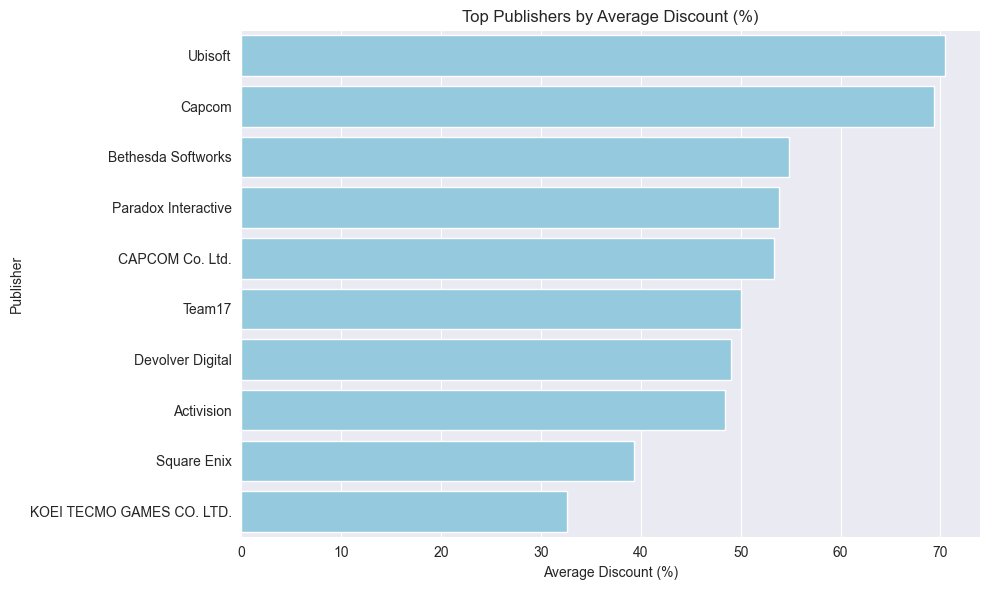

In [108]:
top_publishers = df["publisher"].value_counts().head(10).index
publisher_stats = (
    df[df["publisher"].isin(top_publishers)]
    .groupby("publisher")
    .agg(
        avg_discount=("discount_percent", "mean"),
        avg_positive_ratio=("positive_ratio", "mean"),
        avg_price=("base_price", "mean")
    )
    .sort_values("avg_discount", ascending=False)
)

plt.figure(figsize=(10,6))
sns.barplot(y=publisher_stats.index, x=publisher_stats["avg_discount"], color="skyblue")
plt.title("Top Publishers by Average Discount (%)")
plt.xlabel("Average Discount (%)")
plt.ylabel("Publisher")
plt.tight_layout()
plt.show()

# Heatmap

Going to build a heatmap to search for correlations

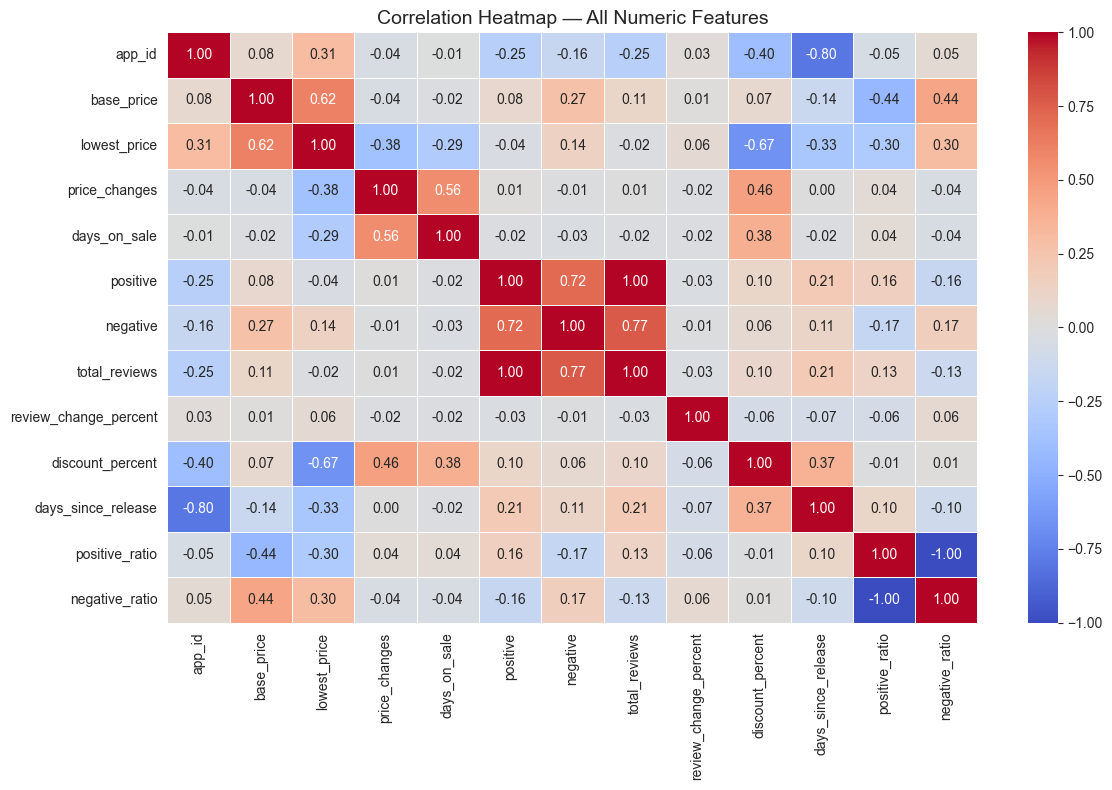

In [109]:
numeric_df = df.select_dtypes(include=["number"])

corr = numeric_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap — All Numeric Features", fontsize=14)
plt.tight_layout()
plt.show()


The most important features for discount percent are
- days since release (0.35)
- days on sale (0.40)
- price changes (0.44)
- lowest price (-0.65) (since its a part of discount percent we will not use it for predictions)

Even though reviews barely correlate with discount percent (since this type of heatmap shows only linear correlations), they are still important features for prediction.

# Building a model
I will use a random forest regressor to predict discount percent.

data cleaning and preparation

In [110]:
# drop weird or missing values
df = df.dropna(subset=[
    'app_id', 'month', 'base_price', 'lowest_price', 'discount_percent',
    'days_since_release', 'days_on_sale', 'price_changes', 'positive_ratio',
    'negative_ratio', 'total_reviews', 'review_change_percent', 'publisher'
])

# make review_change_percent numeric
df["review_change_percent"] = (
    df["review_change_percent"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.replace("-", "0", regex=False)
    .astype(float)
)

# convert month to datetime if it's not
if not pd.api.types.is_datetime64_any_dtype(df["month"]):
    df["month"] = pd.to_datetime(df["month"], errors="coerce")

# just for model convenience
df["month_num"] = df["month"].dt.month

encoding

In [111]:
df = pd.get_dummies(df, columns=["publisher"], drop_first=True)

df = df.drop_duplicates().reset_index(drop=True)

time-based split per game

In [112]:
# split train/test by time for each game
train_idx, test_idx = [], []

for game_id, group in df.groupby("app_id"):
    group = group.sort_values("month")

    # 80% older months go to train, rest to test
    split_point = int(len(group) * 0.8)
    train_idx.extend(group.index[:split_point])
    test_idx.extend(group.index[split_point:])

train_df = df.loc[train_idx]
test_df = df.loc[test_idx]

print(f"Train size: {len(train_df)} | Test size: {len(test_df)}")


Train size: 5032 | Test size: 1369


build features

In [113]:
features = [
    'days_since_release',
    'days_on_sale',
    'price_changes',
    'positive_ratio',
    'negative_ratio',
    'total_reviews',
    'base_price',
    'review_change_percent',
    'month_num'
] + [c for c in df.columns if c.startswith("publisher_")]

X_train = train_df[features]
y_train = train_df['discount_percent']

X_test = test_df[features]
y_test = test_df['discount_percent']

print("num of features:", len(features))


num of features: 193


sanity check

In [114]:
# just to make sure split really by time
print("train range:", train_df["month"].min(), "→", train_df["month"].max())
print("test range:", test_df["month"].min(), "→", test_df["month"].max())


train range: 2023-11-01 00:00:00 → 2025-09-01 00:00:00
test range: 2024-07-01 00:00:00 → 2025-10-01 00:00:00


In [115]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# random forest time
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# predictions
y_pred = model.predict(X_test)

# quick check
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.3f}")


MAE: 6.74
R²: 0.827


feature importance

In [116]:
# check which features matter most
imp = pd.Series(model.feature_importances_, index=X_train.columns)
imp = imp.sort_values(ascending=False)

print("\nTop 10 features:")
print(imp.head(10))


Top 10 features:
days_on_sale                                       0.522344
days_since_release                                 0.317816
base_price                                         0.027421
total_reviews                                      0.021515
negative_ratio                                     0.019155
publisher_Activision                               0.017750
positive_ratio                                     0.017460
publisher_KOEI TECMO GAMES CO. LTD.                0.005461
publisher_Mana Potion Studios Pingle Studio Ltd    0.004299
publisher_Xbox Game Studios                        0.003954
dtype: float64


visualize predictions

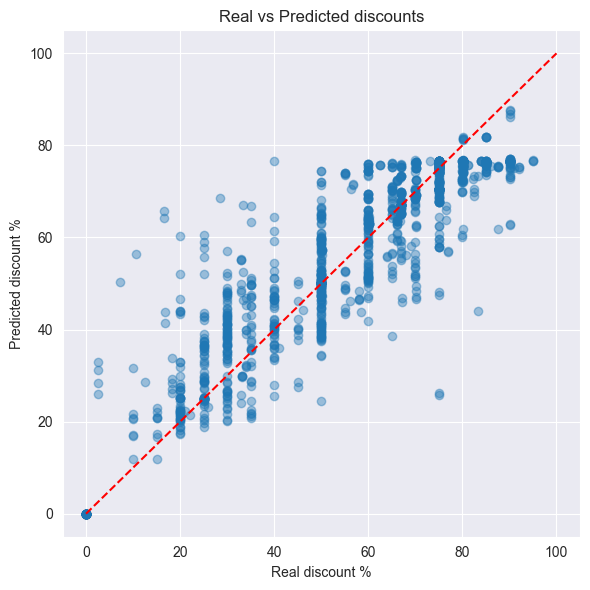

In [117]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Real discount %")
plt.ylabel("Predicted discount %")
plt.title("Real vs Predicted discounts")
plt.plot([0, 100], [0, 100], "r--")  # ideal line
plt.tight_layout()
plt.show()

# Adding another model to compare perfomance

I decided to try XGBoost as a second model because it’s one of the best algorithms for structured tabular data.
It uses gradient boosting, which often performs better than RandomForest by combining many weak trees into a strong model.

In [118]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# train an XGBoost model for comparison
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

# make predictions
y_pred_xgb = xgb_model.predict(X_test)

# evaluate performance
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"XGBoost MAE: {mae_xgb:.2f}")
print(f"XGBoost R²: {r2_xgb:.3f}")

# feature importance
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
print("\nTop 10 XGBoost features:")
print(importances.sort_values(ascending=False).head(10))


XGBoost MAE: 5.20
XGBoost R²: 0.881

Top 10 XGBoost features:
publisher_Mana Potion Studios Pingle Studio Ltd    0.054975
days_on_sale                                       0.054298
publisher_Activision                               0.049043
publisher_KOEI TECMO GAMES CO. LTD.                0.036363
publisher_Jackbox Games Inc.                       0.036325
publisher_Xbox Game Studios                        0.028558
price_changes                                      0.024641
publisher_Fellow Traveller                         0.023456
publisher_BANDAI NAMCO Entertainment               0.023321
publisher_Bethesda id Software                     0.023147
dtype: float32


visualize predictions

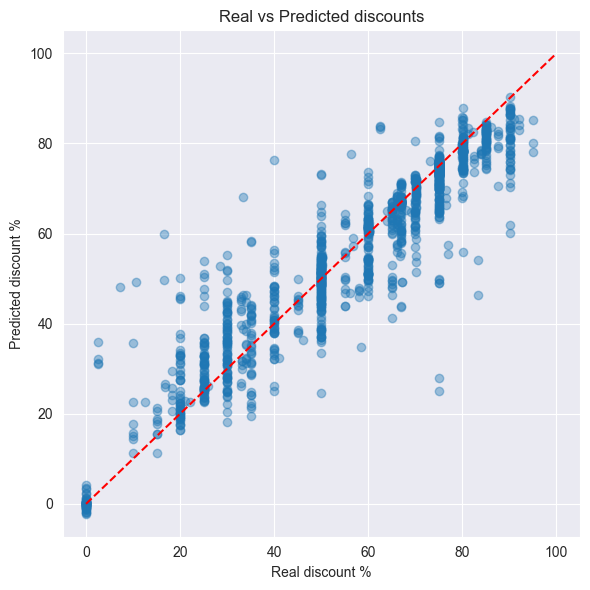

In [119]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_xgb, alpha=0.4)
plt.xlabel("Real discount %")
plt.ylabel("Predicted discount %")
plt.title("Real vs Predicted discounts")
plt.plot([0, 100], [0, 100], "r--")  # ideal line
plt.tight_layout()
plt.show()

results comparison

In [120]:
print("=== Model Comparison ===")
print(f"RandomForest -> MAE: {mae:.2f}, R²: {r2:.3f}")
print(f"XGBoost      -> MAE: {mae_xgb:.2f}, R²: {r2_xgb:.3f}")


=== Model Comparison ===
RandomForest -> MAE: 6.74, R²: 0.827
XGBoost      -> MAE: 5.20, R²: 0.881


# Results and Evaluation
At first, the Random Forest model had a Mean Absolute Error (MAE) of 6.74, meaning that on average, predictions were within about 6–7% of the real discount values. The R² score of 0.827 shows that the model explained around 82% of the variance — which is a pretty good result for real pricing data.

From the scatter plot of real vs predicted discounts, most points follow the diagonal red line, meaning the predictions are close to the real values.

After training XGBoost with the same features, the results got better. The MAE dropped to 5.20, and the R² score increased to 0.881, showing that XGBoost made more accurate predictions and captured more variance. This happened because XGBoost learns from previous errors and handles non-linear patterns better than Random Forest. It also deals well with many categorical features (like publishers), giving them different levels of importance. XGBoost also worked more consistently with the time-based split, showing better adaptation to temporal patterns in the data.

The most important features also changed a bit. While days on sale, days since release, and base price stayed important, several publisher-related features became more significant in XGBoost — for example, Mana Potion Studios Pingle Studio Ltd, Activision, and KOEI TECMO GAMES CO. LTD.. This suggests that different publishers have different discount strategies — some tend to give bigger discounts than others.

Overall, both models captured the main factors affecting game discounts, but XGBoost gave smoother and more precise predictions. It seems that gradient boosting works better for this type of complex pricing data. Adding tags or genres for each game could make the model perform even better.

# Exporting model

In [122]:
import joblib

model.fit(X_train, y_train)
joblib.dump(xgb_model, "xgbModel6500rows/xgb_model.pkl")
joblib.dump(X_train.columns.tolist(), "xgbModel6500rows/xgb_features.pkl")


['xgb_features.pkl']